Exploration du dataset MRI Brain Tumor

In [38]:
from pathlib import Path

chemin_dataset = Path(r"C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data")

print("Chemin utilisé :", chemin_dataset)
print("Le dossier existe :", chemin_dataset.exists())

if chemin_dataset.exists() and chemin_dataset.is_dir():
    for element in chemin_dataset.iterdir():
        if element.is_dir():
            print("[Dossier]", element.name)
        else:
            print("[Fichier]", element.name)

Chemin utilisé : C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data
Le dossier existe : True
[Dossier] Train
[Dossier] Val


In [39]:
from pathlib import Path
from collections import Counter
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

DATASET_DIR = Path(r"C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data")
CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
SPLITS = ["Train", "Val"]

print("Dataset trouvé :", DATASET_DIR.exists())


Dataset trouvé : True


In [40]:
from collections import Counter

extensions_par_classe = {}

for nom_split in ["Train", "Val"]:
    dossier_split = chemin_dataset / nom_split

    for nom_classe in ["Glioma", "Meningioma", "No Tumor", "Pituitary"]:
        dossier_classe = dossier_split / nom_classe
        fichiers = [f for f in dossier_classe.iterdir() if f.is_file()]

        extensions = Counter(f.suffix.lower() for f in fichiers)
        print(f"{nom_split} / {nom_classe} : {len(fichiers)} fichiers — {dict(extensions)}")

Train / Glioma : 0 fichiers — {}
Train / Meningioma : 0 fichiers — {}
Train / No Tumor : 0 fichiers — {}
Train / Pituitary : 0 fichiers — {}
Val / Glioma : 0 fichiers — {}
Val / Meningioma : 0 fichiers — {}
Val / No Tumor : 0 fichiers — {}
Val / Pituitary : 0 fichiers — {}


In [41]:
if not DATASET_DIR.exists():
    print("Chemin incorrect : vérifie DATASET_DIR.")
else:
    for split in SPLITS:
        print(f"\n{split}")
        for classe in CLASSES:
            dossier = DATASET_DIR / split / classe
            print(f"  {classe}: {'OK' if dossier.exists() else 'dossier absent'}")



Train
  Glioma: OK
  Meningioma: OK
  No Tumor: OK
  Pituitary: OK

Val
  Glioma: OK
  Meningioma: OK
  No Tumor: OK
  Pituitary: OK


In [42]:
for nom_split in ["Train", "Val"]:
    dossier_split = chemin_dataset / nom_split
    print(f"\n{nom_split} :")

    for nom_classe in ["Glioma", "Meningioma", "No Tumor", "Pituitary"]:
        dossier_classe = dossier_split / nom_classe
        print(f"  {nom_classe} :")

        for sous_dossier in dossier_classe.iterdir():
            if sous_dossier.is_dir():
                nombre_fichiers = sum(
                    1 for element in sous_dossier.rglob("*") if element.is_file()
                )
                print(f"    {sous_dossier.name} : {nombre_fichiers} fichiers")


Train :
  Glioma :
    images : 1153 fichiers
    labels : 1153 fichiers
  Meningioma :
    images : 1449 fichiers
    labels : 1449 fichiers
  No Tumor :
    images : 711 fichiers
    labels : 711 fichiers
  Pituitary :
    images : 1424 fichiers
    labels : 1424 fichiers

Val :
  Glioma :
    images : 136 fichiers
    labels : 136 fichiers
  Meningioma :
    images : 140 fichiers
    labels : 140 fichiers
  No Tumor :
    images : 100 fichiers
    labels : 100 fichiers
  Pituitary :
    images : 136 fichiers
    labels : 136 fichiers


In [43]:
extensions_images = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
comptes = {}

for split in SPLITS:
    print(f"\n{split}")
    for classe in CLASSES:
        dossier_images = DATASET_DIR / split / classe / "images"
        dossier_labels = DATASET_DIR / split / classe / "labels"

        images = [p for p in dossier_images.iterdir()
                  if p.is_file() and p.suffix.lower() in extensions_images] if dossier_images.exists() else []
        labels = list(dossier_labels.glob("*.txt")) if dossier_labels.exists() else []

        comptes[(split, classe)] = len(images)
        print(f"{classe:12} | images : {len(images):4} | annotations : {len(labels):4}")



Train
Glioma       | images : 1153 | annotations : 1153
Meningioma   | images : 1449 | annotations : 1449
No Tumor     | images :  711 | annotations :  711
Pituitary    | images : 1424 | annotations : 1424

Val
Glioma       | images :  136 | annotations :  136
Meningioma   | images :  140 | annotations :  140
No Tumor     | images :  100 | annotations :  100
Pituitary    | images :  136 | annotations :  136


In [44]:
from PIL import Image

dossier_images = chemin_dataset / "Train" / "Glioma" / "images"
dossier_labels = chemin_dataset / "Train" / "Glioma" / "labels"

fichier_label = sorted(dossier_labels.glob("*.txt"))[0]
fichier_image = dossier_images / (fichier_label.stem + ".jpg")

print("Annotation :", fichier_label.name)
print("Image correspondante :", fichier_image.name)
print("L'image existe :", fichier_image.exists())
print("Contenu de l'annotation :", fichier_label.read_text(encoding="utf-8").strip())

if fichier_image.exists():
    with Image.open(fichier_image) as image:
        print("Dimensions de l'image (largeur, hauteur) :", image.size)
        print("Mode de couleur :", image.mode)

Annotation : gg (1).txt
Image correspondante : gg (1).jpg
L'image existe : True
Contenu de l'annotation : 0 0.567383 0.519531 0.189453 0.148438
Dimensions de l'image (largeur, hauteur) : (512, 512)
Mode de couleur : RGB


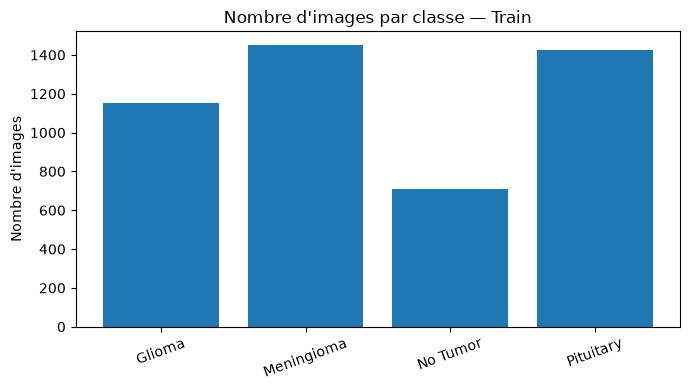

{'Glioma': 1153, 'Meningioma': 1449, 'No Tumor': 711, 'Pituitary': 1424}


In [45]:
comptes_train = {
    classe: comptes.get(("Train", classe), 0)
    for classe in CLASSES
}

plt.figure(figsize=(7, 4))
plt.bar(comptes_train.keys(), comptes_train.values())
plt.title("Nombre d'images par classe — Train")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print(comptes_train)


In [46]:
from PIL import Image

with Image.open(fichier_image) as image:
    print("Image lisible :", image.format)
    print("Dimensions :", image.size)
    print("Mode de couleur :", image.mode)

Image lisible : JPEG
Dimensions : (512, 512)
Mode de couleur : RGB


In [47]:
problemes_images = []
annotations_manquantes = []

for split in SPLITS:
    for classe in CLASSES:
        dossier = DATASET_DIR / split / classe
        dossier_images = dossier / "images"
        dossier_labels = dossier / "labels"

        if not dossier_images.exists():
            continue

        for chemin_image in dossier_images.iterdir():
            if not chemin_image.is_file() or chemin_image.suffix.lower() not in extensions_images:
                continue

            try:
                with Image.open(chemin_image) as img:
                    img.verify()
            except Exception:
                problemes_images.append(str(chemin_image))

            fichier_label = dossier_labels / f"{chemin_image.stem}.txt"
            if not fichier_label.exists():
                annotations_manquantes.append(str(chemin_image))

print("Images illisibles :", len(problemes_images))
print("Images sans fichier d'annotation :", len(annotations_manquantes))

for chemin in problemes_images[:10]:
    print("Image illisible :", chemin)
for chemin in annotations_manquantes[:10]:
    print("Annotation manquante :", chemin)


Images illisibles : 0
Images sans fichier d'annotation : 2
Annotation manquante : C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Val\No Tumor\images\image(55).jpg
Annotation manquante : C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Val\No Tumor\images\image(61).jpg


In [48]:
import os

os.startfile(str(fichier_image))

In [49]:
problemes_labels = []
nombre_boites = 0
labels_vides = 0

for split in SPLITS:
    for classe in CLASSES:
        dossier_labels = DATASET_DIR / split / classe / "labels"
        if not dossier_labels.exists():
            continue

        for fichier in dossier_labels.glob("*.txt"):
            lignes = fichier.read_text(encoding="utf-8").splitlines()

            if not any(ligne.strip() for ligne in lignes):
                labels_vides += 1
                continue

            for numero, ligne in enumerate(lignes, start=1):
                if not ligne.strip():
                    continue

                valeurs = ligne.split()
                try:
                    nombres = [float(v) for v in valeurs]
                except ValueError:
                    problemes_labels.append(f"{fichier.name}, ligne {numero} : valeur non numérique")
                    continue

                if len(nombres) != 5:
                    problemes_labels.append(f"{fichier.name}, ligne {numero} : {len(nombres)} valeurs")
                    continue

                class_id, xc, yc, largeur, hauteur = nombres

                if class_id < 0 or not class_id.is_integer():
                    problemes_labels.append(f"{fichier.name}, ligne {numero} : class_id invalide")
                elif not all(0 <= v <= 1 for v in [xc, yc, largeur, hauteur]):
                    problemes_labels.append(f"{fichier.name}, ligne {numero} : coordonnées hors de [0, 1]")
                elif largeur <= 0 or hauteur <= 0:
                    problemes_labels.append(f"{fichier.name}, ligne {numero} : largeur ou hauteur nulle")
                else:
                    nombre_boites += 1

print("Boîtes valides :", nombre_boites)
print("Fichiers d'annotation vides :", labels_vides)
print("Lignes d'annotation problématiques :", len(problemes_labels))

for probleme in problemes_labels[:20]:
    print("-", probleme)


Boîtes valides : 5873
Fichiers d'annotation vides : 1
Lignes d'annotation problématiques : 0


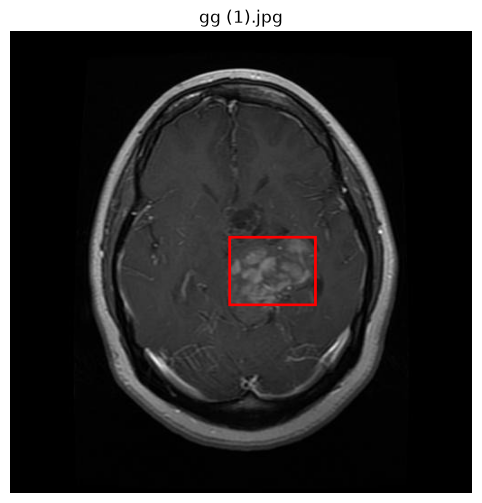

In [52]:

from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# 1. Choisir une image et son annotation
dossier = DATASET_DIR / "Train" / "Glioma"

fichier_label = next((dossier / "labels").glob("*.txt"))
fichier_image = dossier / "images" / (fichier_label.stem + ".jpg")

# 2. Charger l'image
with Image.open(fichier_image) as img:
    image = img.convert("RGB")

# 3. Lire la première bounding box valide
lignes = fichier_label.read_text(encoding="utf-8").splitlines()
valeurs = lignes[0].split()

class_id, centre_x, centre_y, largeur, hauteur = map(float, valeurs)

# 4. Convertir les coordonnées YOLO en pixels
W, H = image.size

x_min = (centre_x - largeur / 2) * W
y_min = (centre_y - hauteur / 2) * H
x_max = (centre_x + largeur / 2) * W
y_max = (centre_y + hauteur / 2) * H

# 5. Dessiner la boîte et afficher l'image
image_avec_boite = image.copy()
dessin = ImageDraw.Draw(image_avec_boite)
dessin.rectangle((x_min, y_min, x_max, y_max), outline="red", width=3)

plt.figure(figsize=(6, 6))
plt.imshow(image_avec_boite)
plt.title(fichier_image.name)
plt.axis("off")
plt.show()


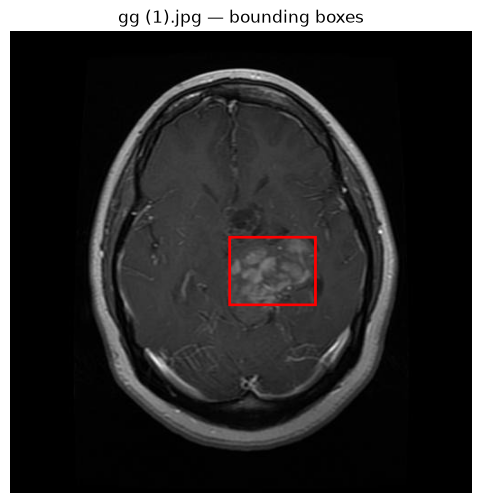

Image : gg (1).jpg
Annotation : gg (1).txt
Dimensions : (512, 512)


In [53]:
classe_a_afficher = "Glioma"
dossier_images = DATASET_DIR / "Train" / classe_a_afficher / "images"
dossier_labels = DATASET_DIR / "Train" / classe_a_afficher / "labels"

fichier_image = None
fichier_label = None

if dossier_images.exists() and dossier_labels.exists():
    for label in sorted(dossier_labels.glob("*.txt")):
        image_candidate = next(
            (dossier_images / f"{label.stem}{ext}" for ext in extensions_images
             if (dossier_images / f"{label.stem}{ext}").exists()),
            None
        )
        if image_candidate and label.read_text(encoding="utf-8").strip():
            fichier_image = image_candidate
            fichier_label = label
            break

if fichier_image is None:
    print("Aucune image annotée trouvée pour cette classe.")
else:
    with Image.open(fichier_image) as img:
        image = img.convert("RGB")

    dessin = ImageDraw.Draw(image)

    for ligne in fichier_label.read_text(encoding="utf-8").splitlines():
        valeurs = ligne.split()
        if len(valeurs) != 5:
            continue

        try:
            class_id, xc, yc, w, h = map(float, valeurs)
        except ValueError:
            continue

        x1 = (xc - w / 2) * image.width
        y1 = (yc - h / 2) * image.height
        x2 = (xc + w / 2) * image.width
        y2 = (yc + h / 2) * image.height

        dessin.rectangle((x1, y1, x2, y2), outline="red", width=3)

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(f"{fichier_image.name} — bounding boxes")
    plt.axis("off")
    plt.show()

    print("Image :", fichier_image.name)
    print("Annotation :", fichier_label.name)
    print("Dimensions :", image.size)


In [54]:
Nombre de problèmes : 550
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (115).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (118).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (126).txt : 15 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (127).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (129).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (130).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (139).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (143).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (159).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (160).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (161).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (164).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (165).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (166).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (167).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (169).txt : 15 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (17).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (170).txt : 10 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (171).txt : 15 valeurs au lieu de 5
- C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data\Train\Glioma\labels\gg (172).txt : 10 valeurs au lieu de 5

SyntaxError: invalid syntax (4081372804.py, line 1)

In [ ]:
print("Résumé de l'exploration")
print("-----------------------")
print("Images illisibles :", len(problemes_images))
print("Annotations manquantes :", len(annotations_manquantes))
print("Lignes d'annotation problématiques :", len(problemes_labels))
print("Fichiers d'annotation vides :", labels_vides)

if problemes_images or annotations_manquantes or problemes_labels:
    print("\nÀ vérifier avant de passer au prétraitement.")
else:
    print("\nAucun problème détecté par ces contrôles simples.")
